# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


In [1]:
import hashlib
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 600                       # used by the bootstrap later; recorded in decisions.md when it matters
rng = np.random.default_rng(SEED)

RAW = Path("data/raw")
FIG = Path("fig")
FIG.mkdir(exist_ok=True)

# The files this notebook reads, with the SHA-256 from data/README.md.
# 2021 is not read (decisions.md, 2026-11-06).
FILES = {
    2022: ("NSDUH-2022-DS0001-bndl-data-tsv_v2.zip", "cde54c4af548de3cacebff00127fda4ffa645fb9cd4803dbd0ae9ed3df1c799f"),
    2023: ("nsduh-2023-ds0001-bndl-data-tsv_v2.zip", "f2ed2fb234ebe04b6548e827fd90138830bb6bc8411e215a526d0ef3ddcd9324"),
    2024: ("NSDUH-2024-DS0001-bndl-data-tsv_v1.zip", "a26f3009991e848c9a6b594e5d57906621a75459c7ba51d10b409ed2f8432a8f"),
}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

for year, (name, expected) in FILES.items():
    got = sha256(RAW / name)
    assert got == expected, f"{name}: SHA-256 {got} does not match data/README.md"
print(f"{len(FILES)} files match the SHA-256 in data/README.md")


3 files match the SHA-256 in data/README.md


## Question

One sentence, then the quantity with units and a time window. Save the layer diagram, data to model to prediction to decision, as `fig/layers.png`.

![Layer diagram](fig/layers.png)


**Question.** Counselors can watch only some new FirstHarbor clients closely in their first week. Among adults in mental-health treatment, do a few intake answers pick out who is having serious thoughts of suicide well enough to decide who gets those slots?

**Quantity.** For an adult who received mental-health treatment in the past 12 months, whether they seriously thought about killing themselves in the past 12 months. Scored on the 2023 survey, and checked on 2024, as the share of at-risk clients who get a close-monitoring slot when counselors can watch a given share of new clients, and as at-risk clients on close monitoring per 100 new clients.

**Decision.** As FirstHarbor's founder, I decide whether to build intake screening and which rule fills the slots. Loss per 100 new clients: L = r · FN + FP, where FN counts at-risk clients on standard monitoring, FP counts low-risk clients on close monitoring, and r is the cost of a miss in units of one unneeded week of close monitoring, between 2 and 500 (`REFERENCES.md`). The costlier mistake is the miss (FN). When K slots per 100 are all filled and C of them go to at-risk clients, out of A at-risk clients, L = r · (A − C) + (K − C). So with the slots fixed, the lowest loss is the most at-risk clients caught, whatever r is. r decides two other things: whether all the slots are worth filling, and whether more counselor time is worth paying for.

This question replaced the first one on 2026-11-07 (`decisions.md`). The first one, whether sorting clients by risk costs less than starting everyone at the same level, is still answered below. It is the check for what to do if counselor time were unlimited.

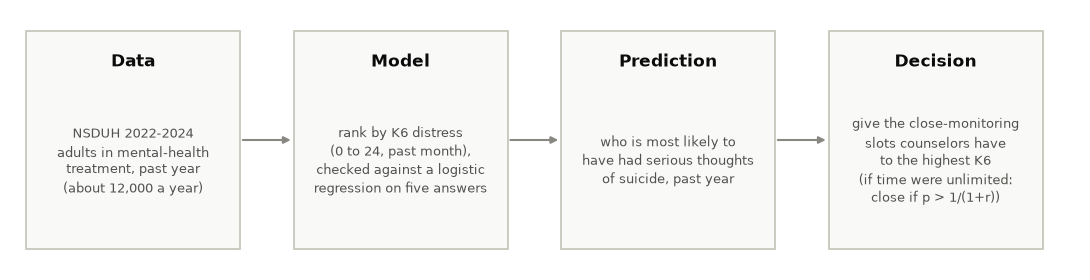

In [2]:
# Layer diagram: data -> model -> prediction -> decision.
layers = [
    ("Data", "NSDUH 2022-2024\nadults in mental-health\ntreatment, past year\n(about 12,000 a year)"),
    ("Model", "rank by K6 distress\n(0 to 24, past month),\nchecked against a logistic\nregression on five answers"),
    ("Prediction", "who is most likely to\nhave had serious thoughts\nof suicide, past year"),
    ("Decision", "give the close-monitoring\nslots counselors have\nto the highest K6\n(if time were unlimited:\nclose if p > 1/(1+r))"),
]
fig, ax = plt.subplots(figsize=(11, 2.9))
ax.set_xlim(0, 4); ax.set_ylim(0, 1); ax.axis("off")
for i, (head, body) in enumerate(layers):
    ax.add_patch(plt.Rectangle((i + 0.06, 0.08), 0.8, 0.84, facecolor="#f9f9f7", edgecolor="#c3c2b7", lw=1.2))
    ax.text(i + 0.46, 0.80, head, ha="center", va="center", fontsize=12, color="#0b0b0b", weight="bold")
    ax.text(i + 0.46, 0.42, body, ha="center", va="center", fontsize=9.5, color="#52514e", linespacing=1.4)
    if i < 3:
        ax.annotate("", xy=(i + 1.06, 0.5), xytext=(i + 0.86, 0.5),
                    arrowprops=dict(arrowstyle="-|>", color="#898781", lw=1.5))
fig.tight_layout(); fig.savefig(FIG / "layers.png", dpi=150); plt.show()


## Data

Download the release into this folder, with `OWNER/REPO` your fork:

```bash
gh release download data --dir data --repo OWNER/REPO
```

If the terms do not let you republish the files, there is no release: run the download command in `data/README.md` instead. The upload commands are in `data/README.md` too. Read the files from `data/`. Show one plot of the raw data and one table of summary statistics before any model. Save the plot under `fig/`.


,adults,in treatment,share in treatment (wtd),"at risk, n","at risk, rate (wtd)",role
2022,47100,11978,21.5%,2014,13.4%,train
2023,45133,11851,23.1%,1938,12.7%,test
2024,47299,12444,23.0%,1814,11.9%,check (new wording)


n by year,2022,2023,2024
age,,,
18-25,3914,3689,3753
26-34,2610,2591,2806
35-49,3423,3539,3733
50-64,1187,1157,1237
65+,844,875,915


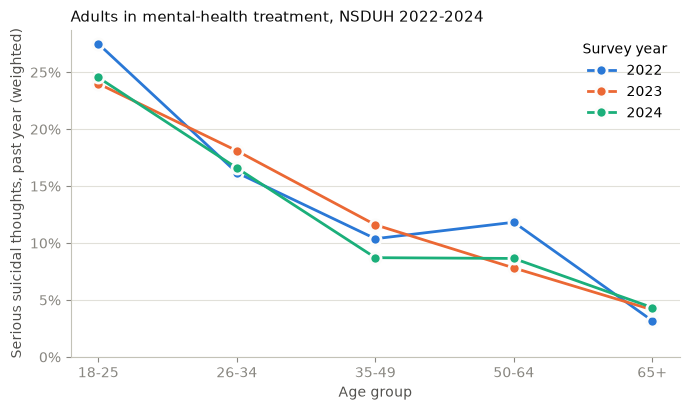

In [3]:
# "In treatment" is MHTRTPY in 2022-2023 and MHTRTPY2 in 2024; SAMHSA says 2024 is not comparable.
TRT = {2022: "MHTRTPY", 2023: "MHTRTPY", 2024: "MHTRTPY2"}
COLS = ["QUESTID2", "CATAG6", "IRSUICTHNK", "ANALWT2_C", "VESTR_C", "VEREP",
        "KSSLR6MON", "UD5ILALANY", "IRMHTRXMED", "IRMHTPHVID"]   # the five intake predictors (with CATAG6)
# Candidate extra predictors, used only in the alternatives check near the end (decisions.md, 2026-11-10):
# sex, overall health, employment, and depression symptoms 1 to 8 (symptom 9 is thoughts of death, so it is left out).
EXTRA = ["IRSEX", "HEALTH2", "IRWRKSTAT18"] + [f"AD_MDEA{k}" for k in range(1, 9)]
AGE = {2: "18-25", 3: "26-34", 4: "35-49", 5: "50-64", 6: "65+"}

def load(year):
    """Read one year's TSV straight from its zip, without unzipping."""
    with zipfile.ZipFile(RAW / FILES[year][0]) as zf:
        (name,) = zf.namelist()          # each zip holds exactly one file
        with zf.open(name) as fh:
            d = pd.read_csv(fh, sep="\t", usecols=COLS + EXTRA + [TRT[year]])
    return d.rename(columns={TRT[year]: "in_trt"}).assign(year=year)

everyone = pd.concat([load(y) for y in FILES], ignore_index=True)
adults = everyone[everyone.CATAG6 >= 2]
df = adults[adults.in_trt == 1].copy()          # the population: adults in MH treatment, past year
df["at_risk"] = df.IRSUICTHNK.astype(int)       # serious suicidal thoughts, past year (imputation-revised)
df["age"] = pd.Categorical(df.CATAG6.map(AGE), categories=list(AGE.values()), ordered=True)
assert df.at_risk.isin([0, 1]).all()
assert df.KSSLR6MON.between(0, 24).all()
assert df[["UD5ILALANY", "IRMHTRXMED", "IRMHTPHVID"]].isin([0, 1]).all().all()

def wmean(x, w):
    return (x * w).sum() / w.sum()

summary = pd.DataFrame({
    "adults": adults.groupby("year").size(),
    "in treatment": df.groupby("year").size(),
    "share in treatment (wtd)": adults.groupby("year").apply(lambda g: wmean(g.in_trt == 1, g.ANALWT2_C)),
    "at risk, n": df.groupby("year").at_risk.sum(),
    "at risk, rate (wtd)": df.groupby("year").apply(lambda g: wmean(g.at_risk, g.ANALWT2_C)),
    "role": pd.Series({2022: "train", 2023: "test", 2024: "check (new wording)"}),
})
pct = ["share in treatment (wtd)", "at risk, rate (wtd)"]
display(summary.assign(**{k: summary[k].map("{:.1%}".format) for k in pct}))

by_age = (df.groupby(["year", "age"], observed=True)
            .apply(lambda g: pd.Series({"n": len(g), "rate": wmean(g.at_risk, g.ANALWT2_C)}))
            .reset_index())
display(by_age.pivot(index="age", columns="year", values="n").astype(int).rename_axis(columns="n by year"))

# Raw-data plot: weighted rate of serious suicidal thoughts by age group, one line per year.
COLORS = {2022: "#2a78d6", 2023: "#eb6834", 2024: "#1baf7a"}   # categorical slots 1-3, fixed order
fig, ax = plt.subplots(figsize=(7, 4.2))
for year, g in by_age.groupby("year"):
    ax.plot(g.age.astype(str), g.rate, color=COLORS[year], lw=2, marker="o", ms=8,
            markeredgecolor="#fcfcfb", markeredgewidth=2, label=str(year))
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Age group", color="#52514e")
ax.set_ylabel("Serious suicidal thoughts, past year (weighted)", color="#52514e")
ax.set_title("Adults in mental-health treatment, NSDUH 2022-2024", loc="left", fontsize=11, color="#0b0b0b")
ax.grid(axis="y", color="#e1e0d9", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False, title="Survey year", loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "raw_rate_by_age.png", dpi=150)
plt.show()


**Reading.** About 12,000 adults in treatment per year, about 1,800 to 2,000 of them at risk. The weighted rate falls every year: 13.4%, 12.7%, 11.9%. Age is the clearest pattern in the raw data: about a quarter of 18–25-year-olds in treatment report serious thoughts of suicide, against 3–4% at 65 and over.

How the measurement differs from what the decision needs (`PROPOSAL.md`): FirstHarbor's clients are invited by a counselor, not drawn at random; the answers cover the past year, not the moment of intake; and they are given to a survey, not a clinical app. All three are bias, not noise. "In treatment" is also defined differently in 2024.

## Split

Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.


In [4]:
# Split by survey year (decisions.md, 2026-11-06). No random draw.
train = df[df.year == 2022]
test = df[df.year == 2023]      # same treatment definition as train
check = df[df.year == 2024]     # new treatment wording from June 2024: a shift check, never used to fit or choose
for name, d in [("train 2022", train), ("test 2023", test), ("check 2024", check)]:
    print(f"{name}: {len(d):>6,} adults in treatment, {d.at_risk.sum():>5,} at risk, "
          f"weighted rate {wmean(d.at_risk, d.ANALWT2_C):.1%}")


train 2022: 11,978 adults in treatment, 2,014 at risk, weighted rate 13.4%
test 2023: 11,851 adults in treatment, 1,938 at risk, weighted rate 12.7%
check 2024: 12,444 adults in treatment, 1,814 at risk, weighted rate 11.9%


## Baseline

A simple method: the mean, the last value, or a plain regression. Score it on the held-out data in the units of the decision.


In [5]:
# Loss per 100 new clients, in units of one unneeded week of close monitoring:
#   L = 100 * (r * P(at risk and put on standard) + P(not at risk and put on close)),
# with probabilities weighted by ANALWT2_C so they describe the population, not the sample.
R_GRID = np.array([2, 5, 10, 14, 29, 35, 40, 50, 100, 150, 300, 500])   # r from 2 to 500 (decisions.md, 2026-10-26)
# 35 and 40 were added on 2026-11-10 to see where between 29 and 50 the savings stop being clear.
R_TICKS = [2, 5, 10, 14, 29, 50, 100, 150, 300, 500]                    # axis labels only

def loss_per_100(at_risk, close, w, r):
    """at_risk, close: 0/1 arrays; w: weights. Returns L for each r."""
    w = np.asarray(w) / np.sum(w)
    fn = np.sum(w * (at_risk == 1) * (close == 0))     # at risk, put on standard monitoring
    fp = np.sum(w * (at_risk == 0) * (close == 1))     # not at risk, put on close monitoring
    return 100 * (np.asarray(r) * fn + fp)

# Baseline: everyone starts at the same level. Which level is cheaper depends on r and on the
# at-risk rate p: all-standard costs 100*r*p, all-close costs 100*(1-p). The choice is made with
# p from the training year only, then scored on the held-out years.
p_train = wmean(train.at_risk, train.ANALWT2_C)
r_switch = (1 - p_train) / p_train
print(f"p (2022, weighted) = {p_train:.3f}; everyone-close is cheaper than everyone-standard when r > {r_switch:.1f}")

def baseline_loss(d, r):
    out = []
    for r_ in np.atleast_1d(r):
        close = np.full(len(d), int(r_ > r_switch))        # one level for everyone, chosen on 2022
        out.append(loss_per_100(d.at_risk.to_numpy(), close, d.ANALWT2_C, r_))
    return np.array(out)

base = pd.DataFrame({
    "r": R_GRID,
    "level (chosen on 2022)": np.where(R_GRID > r_switch, "all close", "all standard"),
    "L all standard, 2023": loss_per_100(test.at_risk.to_numpy(), np.zeros(len(test)), test.ANALWT2_C, R_GRID),
    "L all close, 2023": loss_per_100(test.at_risk.to_numpy(), np.ones(len(test)), test.ANALWT2_C, R_GRID),
    "baseline L, 2023": baseline_loss(test, R_GRID),
    "baseline L, 2024": baseline_loss(check, R_GRID),
}).set_index("r")
display(base.round(1))


p (2022, weighted) = 0.134; everyone-close is cheaper than everyone-standard when r > 6.4


,level (chosen on 2022),"L all standard, 2023","L all close, 2023","baseline L, 2023","baseline L, 2024"
r,,,,,
2,all standard,25.4,87.3,25.4,23.7
5,all standard,63.6,87.3,63.6,59.3
10,all close,127.1,87.3,87.3,88.1
14,all close,178.0,87.3,87.3,88.1
29,all close,368.7,87.3,87.3,88.1
35,all close,445.0,87.3,87.3,88.1
40,all close,508.5,87.3,87.3,88.1
50,all close,635.6,87.3,87.3,88.1
100,all close,1271.3,87.3,87.3,88.1


**Reading.** With 13.4% at risk in 2022, starting everyone on close monitoring is cheaper than starting everyone on standard once r > 6.4. So across almost the whole range of r, the baseline is everyone on close monitoring, at 87.3 per 100 new clients on 2023. A screen can win only by finding clients who are safe to start on standard monitoring.

## Model

Write the model as equations. Say what each parameter means, which assumption you trust least, and fit the model. Score it on the same held-out data, in the same units. State the uncertainty of the prediction.


### The model

The rule this project recommends has no fitted parameters: sort new clients by their K6 distress score and fill the slots from the top (Capacity section, and `decisions.md`, 2026-11-10). The model below is the alternative it was compared with. It is also what the unlimited-time check uses, because a threshold on risk needs a probability.

Logistic regression, fit on 2022 with the survey weights `ANALWT2_C`:

$$\log\frac{p_i}{1-p_i} = \beta_0 + \beta_{\text{age}[i]} + \beta_1\,\text{K6}_i + \beta_2\,\text{SUD}_i + \beta_3\,\text{Rx}_i + \beta_4\,\text{Tele}_i$$

- $p_i$: the probability that adult $i$ in treatment had serious thoughts of suicide in the past year (`IRSUICTHNK`).
- $\beta_{\text{age}}$: one shift per age group, relative to 18–25 (`CATAG6`).
- $\beta_1$: the change in log-odds per point of K6 psychological distress in the past month, 0 to 24 (`KSSLR6MON`).
- $\beta_2$: a drug or alcohol use disorder in the past year (`UD5ILALANY`).
- $\beta_3$: took prescription medication for mental health in the past year (`IRMHTRXMED`).
- $\beta_4$: received mental-health treatment by phone or video in the past year (`IRMHTPHVID`).

The action: close monitoring when $\hat p_i > 1/(1+r)$, the threshold at which $r \cdot \hat p_i$, the expected cost of a miss, exceeds $1 - \hat p_i$, the expected cost of an unneeded week.

The assumption trusted least: K6 enters as a straight line on the log-odds scale. Standard errors below treat the weighted sample as simple random, so they are too narrow. A design-based interval (clusters within strata) comes later.

In [6]:
import statsmodels.api as sm

def design(d):
    X = pd.get_dummies(d.age, prefix="age", drop_first=True, dtype=float)   # 18-25 is the reference
    X["k6"] = d.KSSLR6MON.astype(float)
    X["sud"] = d.UD5ILALANY.astype(float)
    X["rx"] = d.IRMHTRXMED.astype(float)
    X["tele"] = d.IRMHTPHVID.astype(float)
    return sm.add_constant(X)

w_train = train.ANALWT2_C / train.ANALWT2_C.mean()
model = sm.GLM(train.at_risk, design(train), family=sm.families.Binomial(), var_weights=w_train).fit()
coefs = pd.DataFrame({"coef": model.params, "odds ratio": np.exp(model.params),
                      "naive SE": model.bse})
display(coefs.round(3))

def model_loss(d, r):
    p_hat = model.predict(design(d)).to_numpy()
    return np.array([loss_per_100(d.at_risk.to_numpy(), (p_hat > 1 / (1 + r_)).astype(int), d.ANALWT2_C, r_)
                     for r_ in np.atleast_1d(r)])

def share_close(d, r):
    p_hat = model.predict(design(d)).to_numpy()
    return np.array([wmean(p_hat > 1 / (1 + r_), d.ANALWT2_C) for r_ in np.atleast_1d(r)])

scores = pd.DataFrame({
    "r": R_GRID,
    "threshold": 1 / (1 + R_GRID),
    "baseline 2023": baseline_loss(test, R_GRID),
    "model 2023": model_loss(test, R_GRID),
    "share on close, 2023": share_close(test, R_GRID),
    "baseline 2024": baseline_loss(check, R_GRID),
    "model 2024": model_loss(check, R_GRID),
}).set_index("r")
scores["model - baseline, 2023"] = scores["model 2023"] - scores["baseline 2023"]
scores["model - baseline, 2024"] = scores["model 2024"] - scores["baseline 2024"]
display(scores.round(3))

# Calibration in the large: weighted mean prediction against the weighted observed rate.
for name, d in [("train 2022", train), ("test 2023", test), ("check 2024", check)]:
    p_hat = model.predict(design(d))
    print(f"{name}: predicted {wmean(p_hat, d.ANALWT2_C):.1%}, observed {wmean(d.at_risk, d.ANALWT2_C):.1%}")


,coef,odds ratio,naive SE
const,-3.732,0.024,0.111
age_26-34,-0.573,0.564,0.086
age_35-49,-0.844,0.430,0.085
age_50-64,-0.515,0.597,0.088
age_65+,-1.416,0.243,0.148
k6,0.186,1.204,0.006
sud,0.360,1.434,0.062
rx,0.402,1.495,0.075
tele,0.258,1.295,0.065


,threshold,baseline 2023,model 2023,"share on close, 2023",baseline 2024,model 2024,"model - baseline, 2023","model - baseline, 2024"
r,,,,,,,,
2,0.333,25.426,21.264,0.104,23.735,21.922,-4.162,-1.813
5,0.167,63.565,39.276,0.244,59.339,37.848,-24.289,-21.491
10,0.091,87.287,54.538,0.399,88.132,53.577,-32.749,-34.555
14,0.067,87.287,60.745,0.492,88.132,64.563,-26.542,-23.569
29,0.033,87.287,71.740,0.707,88.132,74.515,-15.547,-13.617
35,0.028,87.287,76.761,0.758,88.132,80.789,-10.526,-7.343
40,0.024,87.287,79.074,0.805,88.132,83.705,-8.213,-4.427
50,0.020,87.287,79.742,0.859,88.132,89.867,-7.545,1.734
100,0.010,87.287,84.876,0.976,88.132,88.889,-2.411,0.757


train 2022: predicted 13.4%, observed 13.4%
test 2023: predicted 12.6%, observed 12.7%
check 2024: predicted 12.9%, observed 11.9%


**Reading.** On 2023 the model costs less than the baseline for r from 2 to 150, and ties from r = 300, where its threshold is so low that it puts everyone on close monitoring. Overall calibration: predicted 12.6% against 12.7% observed on 2023, and 12.9% against 11.9% on 2024.

### Uncertainty of the savings

NSDUH samples clusters, not people: each year has 50 variance strata (`VESTR_C`) with 2 clusters each (`VEREP`). People in one cluster resemble each other, so the 12,000 adults per year carry less information than 12,000 independent draws.

Rao-Wu bootstrap, 500 replicates, seed 600. In each replicate, for every stratum, keep one of its two clusters at random and double its weights. Do this independently for 2022, 2023, and 2024. Refit the model on the 2022 replicate, choose the baseline level from the 2022 replicate's rate, and score both on the 2023 and 2024 replicates. The interval is the 2.5th to 97.5th percentile of the savings (model loss minus baseline loss). A jackknife was rejected: the loss jumps at the threshold 1/(1+r), and the jackknife is unreliable for statistics that are not smooth.


In [7]:
B = 500
boot_rng = np.random.default_rng(SEED)

def half_sample(d, rng):
    """Rao-Wu with 2 clusters per stratum: keep one cluster per stratum, double its weights."""
    psus = d.groupby("VESTR_C").VEREP.unique()
    keep = {s: rng.choice(v) for s, v in psus.items()}
    out = d[d.VEREP.to_numpy() == d.VESTR_C.map(keep).to_numpy()].copy()
    out["ANALWT2_C"] = out.ANALWT2_C * 2
    return out

def savings(m, p_tr, d, r_grid):
    """Model loss minus baseline loss on d, at each r, for a model m and a training rate p_tr."""
    p_hat = m.predict(design(d)).to_numpy()
    y, w = d.at_risk.to_numpy(), d.ANALWT2_C
    out = []
    for r_ in r_grid:
        model_L = loss_per_100(y, (p_hat > 1 / (1 + r_)).astype(int), w, r_)
        base_L = loss_per_100(y, np.full(len(d), int(r_ > (1 - p_tr) / p_tr)), w, r_)
        out.append(model_L - base_L)
    return np.array(out)

reps = {"2023": [], "2024": []}
for b in range(B):
    tr, te, ch = half_sample(train, boot_rng), half_sample(test, boot_rng), half_sample(check, boot_rng)
    w = tr.ANALWT2_C / tr.ANALWT2_C.mean()
    m_b = sm.GLM(tr.at_risk, design(tr), family=sm.families.Binomial(), var_weights=w).fit()
    p_b = wmean(tr.at_risk, tr.ANALWT2_C)
    reps["2023"].append(savings(m_b, p_b, te, R_GRID))
    reps["2024"].append(savings(m_b, p_b, ch, R_GRID))

unc = pd.DataFrame({"r": R_GRID}).set_index("r")
for yr, d in [("2023", test), ("2024", check)]:
    arr = np.array(reps[yr])
    unc[f"model - baseline {yr}"] = savings(model, p_train, d, R_GRID)
    unc[f"low {yr}"] = np.percentile(arr, 2.5, axis=0)
    unc[f"high {yr}"] = np.percentile(arr, 97.5, axis=0)
    unc[f"P(model better) {yr}"] = (arr < 0).mean(axis=0)
display(unc.round(2))


,model - baseline 2023,low 2023,high 2023,P(model better) 2023,model - baseline 2024,low 2024,high 2024,P(model better) 2024
r,,,,,,,,
2,-4.16,-5.37,-2.93,1.00,-1.81,-3.87,-0.52,1.00
5,-24.29,-28.23,-20.03,1.00,-21.49,-25.43,-16.77,1.00
10,-32.75,-37.72,-27.77,1.00,-34.55,-38.19,-28.63,1.00
14,-26.54,-31.78,-19.57,1.00,-23.57,-30.41,-19.09,1.00
29,-15.55,-21.53,-5.21,1.00,-13.62,-17.13,-2.95,1.00
35,-10.53,-18.24,-2.37,0.99,-7.34,-14.87,2.27,0.92
40,-8.21,-16.01,-0.22,0.98,-4.43,-12.39,4.91,0.78
50,-7.54,-12.58,3.48,0.91,1.73,-8.36,10.79,0.44
100,-2.41,-5.97,6.32,0.76,0.76,-2.49,20.68,0.27


**Reading.** The savings are below zero, with intervals that exclude zero, for r from 2 to 29 in both 2023 and 2024. On 2023 they still exclude zero at r = 35 and 40. On 2024 they include zero from r = 35. From r = 50 up, both intervals include zero: the data cannot tell whether the screen helps. Where the method wins: r ≤ 29. Where it cannot be told apart from the baseline: r ≥ 50. In between, 2023 says it wins and 2024 cannot tell.

## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


In [8]:
# Simulate outcomes from the fitted model on the real 2022 predictors, with the fitted coefficients
# as the known truth. Refit each simulated data set. If the fit is sound, the refits center on the truth.
S = 200
sim_rng = np.random.default_rng(SEED + 1)
X_train = design(train)
p_true = model.predict(X_train).to_numpy()
fits, sim_age = [], []
for s in range(S):
    y_sim = (sim_rng.random(len(p_true)) < p_true).astype(int)
    fits.append(sm.GLM(y_sim, X_train, family=sm.families.Binomial(), var_weights=w_train).fit().params)
    sim_age.append(pd.Series(y_sim * train.ANALWT2_C.to_numpy()).groupby(train.age.to_numpy(), observed=True).sum()
                   / train.groupby("age", observed=True).ANALWT2_C.sum().to_numpy())
fits = pd.DataFrame(fits)
recovery = pd.DataFrame({"true (fitted on 2022)": model.params, "mean of refits": fits.mean(),
                         "sd of refits": fits.std()})
recovery["bias / sd"] = (recovery["mean of refits"] - recovery["true (fitted on 2022)"]) / recovery["sd of refits"]
print(f"Parameter recovery, {S} simulated data sets")
display(recovery.round(3))

# Simulated data against the real data: the at-risk rate by age group.
sim_age = pd.DataFrame(sim_age)
real_age = train.groupby("age", observed=True).apply(lambda g: wmean(g.at_risk, g.ANALWT2_C))
print("Rate of serious suicidal thoughts by age group, 2022: real vs simulated from the model")
display(pd.DataFrame({"real": real_age.to_numpy(), "simulated, 2.5%": sim_age.quantile(0.025).to_numpy(),
                      "simulated, 97.5%": sim_age.quantile(0.975).to_numpy()},
                     index=real_age.index).round(3))


Parameter recovery, 200 simulated data sets


,true (fitted on 2022),mean of refits,sd of refits,bias / sd
const,-3.732,-3.774,0.186,-0.228
age_26-34,-0.573,-0.572,0.138,0.005
age_35-49,-0.844,-0.839,0.131,0.038
age_50-64,-0.515,-0.499,0.167,0.095
age_65+,-1.416,-1.430,0.323,-0.045
k6,0.186,0.189,0.011,0.306
sud,0.360,0.358,0.110,-0.018
rx,0.402,0.398,0.138,-0.028
tele,0.258,0.253,0.113,-0.044


Rate of serious suicidal thoughts by age group, 2022: real vs simulated from the model


,real,"simulated, 2.5%","simulated, 97.5%"
age,,,
18-25,0.275,0.253,0.298
26-34,0.162,0.141,0.185
35-49,0.104,0.090,0.119
50-64,0.118,0.094,0.142
65+,0.032,0.018,0.053


**Reading.** The fit recovers the known coefficients: every refit average is within 0.3 standard deviations of the truth. Data simulated from the model look like the real data: the real rate in every age group lies inside the simulated 95% range, including the 2022 rise at 50–64, which is consistent with chance.

## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


Calibration by decile of predicted risk, 2023


,n,predicted,observed,se,residual,residual / se
bin,,,,,,
1,1193.0,0.015,0.013,0.005,-0.002,-0.371
2,1185.0,0.027,0.020,0.007,-0.008,-1.084
3,1182.0,0.040,0.039,0.010,-0.001,-0.141
4,1196.0,0.056,0.068,0.013,0.012,0.935
5,1178.0,0.078,0.094,0.015,0.017,1.111
6,1181.0,0.109,0.120,0.017,0.011,0.646
7,1188.0,0.155,0.167,0.019,0.012,0.622
8,1179.0,0.222,0.219,0.021,-0.002,-0.112
9,1193.0,0.333,0.345,0.025,0.011,0.450


Calibration by decile of predicted risk, 2024


,n,predicted,observed,se,residual,residual / se
bin,,,,,,
1,1313.0,0.015,0.019,0.006,0.004,0.706
2,1238.0,0.028,0.016,0.006,-0.013,-2.027
3,1204.0,0.041,0.030,0.009,-0.011,-1.202
4,1223.0,0.057,0.085,0.015,0.028,1.934
5,1264.0,0.078,0.052,0.011,-0.026,-2.466
6,1242.0,0.108,0.103,0.015,-0.006,-0.358
7,1227.0,0.150,0.159,0.019,0.009,0.464
8,1258.0,0.218,0.221,0.022,0.004,0.163
9,1237.0,0.330,0.288,0.023,-0.042,-1.867


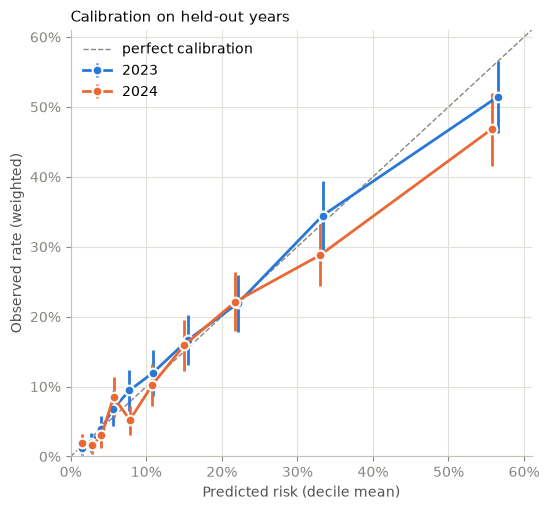

Observed vs predicted by K6 band, train 2022


,n,predicted,observed,se,residual,residual / se
bin,,,,,,
0-4,3465.0,0.028,0.024,0.005,-0.004,-0.868
5-8,3188.0,0.074,0.065,0.008,-0.008,-1.060
9-12,2568.0,0.160,0.176,0.014,0.016,1.164
13-16,1595.0,0.299,0.339,0.022,0.040,1.848
17-20,810.0,0.457,0.423,0.034,-0.033,-0.980
21-24,352.0,0.671,0.597,0.055,-0.074,-1.340


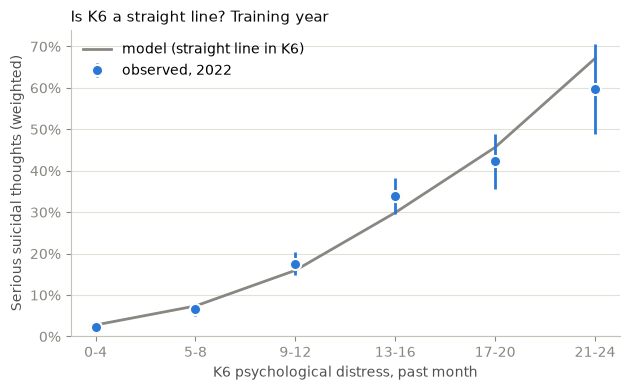

In [9]:
# 1. Calibration and residuals: bin the predictions into deciles, then compare the weighted observed
#    rate with the weighted mean prediction in each bin. Residual = observed - predicted.
#    The interval uses Kish's effective sample size, which allows for unequal weights but not for
#    clustering, so it is still somewhat too narrow.
def binned(d, by, bins):
    t = pd.DataFrame({"p_hat": model.predict(design(d)).to_numpy(), "y": d.at_risk.to_numpy(),
                      "w": d.ANALWT2_C.to_numpy(), "by": by})
    t["bin"] = bins(t.by)
    def agg(g):
        n_eff = g.w.sum() ** 2 / (g.w ** 2).sum()
        obs = wmean(g.y, g.w)
        return pd.Series({"n": len(g), "predicted": wmean(g.p_hat, g.w), "observed": obs,
                          "se": np.sqrt(obs * (1 - obs) / n_eff)})
    out = t.groupby("bin", observed=True).apply(agg)
    out["residual"] = out.observed - out.predicted
    out["residual / se"] = out.residual / out.se
    return out

deciles = lambda s: pd.qcut(s, 10, labels=range(1, 11))
cal = {name: binned(d, model.predict(design(d)).to_numpy(), deciles)
       for name, d in [("2023", test), ("2024", check)]}
for name, t in cal.items():
    print(f"Calibration by decile of predicted risk, {name}")
    display(t.round(3))

COLORS_CAL = {"2023": "#2a78d6", "2024": "#eb6834"}   # categorical slots 1-2
fig, ax = plt.subplots(figsize=(5.6, 5.2))
top = max(t[["predicted", "observed"]].to_numpy().max() for t in cal.values()) * 1.08
ax.plot([0, top], [0, top], color="#898781", lw=1, ls="--", label="perfect calibration")
for name, t in cal.items():
    ax.errorbar(t.predicted, t.observed, yerr=1.96 * t.se, color=COLORS_CAL[name], lw=2, marker="o", ms=7,
                markeredgecolor="#fcfcfb", markeredgewidth=1.5, capsize=0, label=name)
ax.set_xlim(0, top); ax.set_ylim(0, top)
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("Predicted risk (decile mean)", color="#52514e")
ax.set_ylabel("Observed rate (weighted)", color="#52514e")
ax.set_title("Calibration on held-out years", loc="left", fontsize=11, color="#0b0b0b")
ax.grid(color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
for side in ("left", "bottom"): ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "calibration.png", dpi=150); plt.show()

# 2. The assumption trusted least: K6 enters as a straight line on the log-odds scale.
#    On the training year, compare the observed rate in each K6 band with the mean prediction.
k6_bands = lambda s: pd.cut(s, [-1, 4, 8, 12, 16, 20, 24], labels=["0-4", "5-8", "9-12", "13-16", "17-20", "21-24"])
k6 = binned(train, train.KSSLR6MON.to_numpy(), k6_bands)
print("Observed vs predicted by K6 band, train 2022")
display(k6.round(3))

fig, ax = plt.subplots(figsize=(6.4, 4))
x = np.arange(len(k6))
ax.plot(x, k6.predicted, color="#898781", lw=2, label="model (straight line in K6)")
ax.errorbar(x, k6.observed, yerr=1.96 * k6.se, color="#2a78d6", lw=0, elinewidth=2, marker="o", ms=8,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5, label="observed, 2022")
ax.set_xticks(x, k6.index.astype(str))
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, None)
ax.set_xlabel("K6 psychological distress, past month", color="#52514e")
ax.set_ylabel("Serious suicidal thoughts (weighted)", color="#52514e")
ax.set_title("Is K6 a straight line? Training year", loc="left", fontsize=11, color="#0b0b0b")
ax.grid(axis="y", color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
for side in ("left", "bottom"): ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "k6_check.png", dpi=150); plt.show()


**Reading.** Noise or bias? On 2023, nine of the ten residuals are within about 1.1 standard errors of zero: noise. The top decile is over-predicted (56.5% predicted, 51.4% observed, 1.9 standard errors). On 2024 the over-prediction at the top grows (55.7% against 46.8%, 3.3 standard errors): bias, growing with distance from the training data, both in time and in the definition of treatment. Overall calibration is off by 0.1 point on 2023 and 1.0 point on 2024.

This bias does not change any action: for r ≥ 5 every threshold is 17% or less, and clients predicted at 50% get close monitoring either way.

The assumption trusted least, K6 as a straight line on the log-odds scale, holds within about two standard errors in every band. The top band, K6 21–24, is the miss (fit 67%, observed 60%), the same over-prediction.

## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


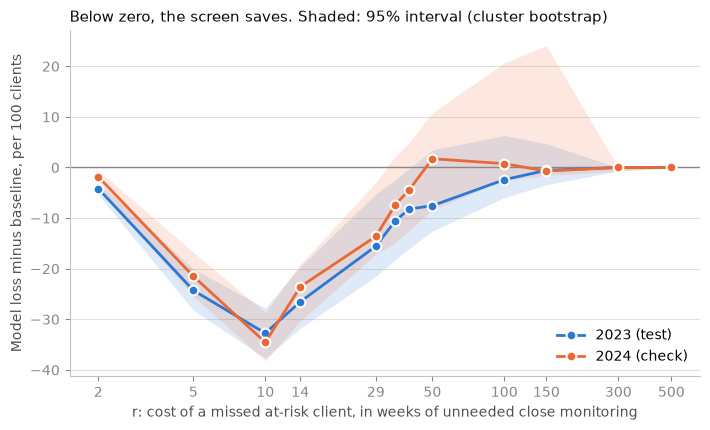

Share of new clients put on close monitoring (2023), by r


,threshold 1/(1+r),share on close
r,,
2,0.333,0.104
5,0.167,0.244
10,0.091,0.399
14,0.067,0.492
29,0.033,0.707
35,0.028,0.758
40,0.024,0.805
50,0.020,0.859
100,0.010,0.976


Loss per 100 clients, 2023: what a better model could still save


,baseline (no screen),model,perfect screen,model's savings,share of the possible savings,left for a better model
r,,,,,,
2,25.43,21.26,0.0,4.16,0.16,21.26
5,63.56,39.28,0.0,24.29,0.38,39.28
10,87.29,54.54,0.0,32.75,0.38,54.54
14,87.29,60.75,0.0,26.54,0.30,60.75
29,87.29,71.74,0.0,15.55,0.18,71.74
35,87.29,76.76,0.0,10.53,0.12,76.76
40,87.29,79.07,0.0,8.21,0.09,79.07
50,87.29,79.74,0.0,7.54,0.09,79.74
100,87.29,84.88,0.0,2.41,0.03,84.88


Loss per 100 clients on 2023, by training size


,model on all of 2022,model on half of 2022 (mean of 100),cost of halving the data
r,,,
2,21.26,21.32,0.06
5,39.28,39.34,0.07
10,54.54,54.48,-0.06
14,60.75,61.15,0.41
29,71.74,73.64,1.90
35,76.76,76.67,-0.09
40,79.07,79.09,0.01
50,79.74,81.57,1.83
100,84.88,86.09,1.22


Risk of the action on 2023: at-risk clients put on standard monitoring


,at-risk clients missed (share of at-risk),missed per 100 new clients,rate among clients on standard
r,,,
2,0.619,7.865,0.088
5,0.362,4.598,0.061
10,0.196,2.491,0.041
14,0.127,1.619,0.032
29,0.036,0.459,0.016
35,0.030,0.379,0.016
40,0.022,0.275,0.014
50,0.010,0.129,0.009
100,0.000,0.000,0.000


In [10]:
# 1. The rule: close monitoring when predicted risk > 1/(1+r). The savings and their 95% interval, by r.
COLORS_YR = {"2023": "#2a78d6", "2024": "#eb6834"}   # categorical slots 1-2
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.axhline(0, color="#898781", lw=1)
for yr in ["2023", "2024"]:
    ax.fill_between(R_GRID, unc[f"low {yr}"], unc[f"high {yr}"], color=COLORS_YR[yr], alpha=0.15, lw=0)
    ax.plot(R_GRID, unc[f"model - baseline {yr}"], color=COLORS_YR[yr], lw=2, marker="o", ms=7,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=f"{yr} ({'test' if yr == '2023' else 'check'})")
ax.set_xscale("log")
ax.set_xticks(R_TICKS, [str(r) for r in R_TICKS])
ax.minorticks_off()
ax.set_xlabel("r: cost of a missed at-risk client, in weeks of unneeded close monitoring", color="#52514e")
ax.set_ylabel("Model loss minus baseline, per 100 clients", color="#52514e")
ax.set_title("Below zero, the screen saves. Shaded: 95% interval (cluster bootstrap)", loc="left", fontsize=11, color="#0b0b0b")
ax.grid(axis="y", color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
for side in ("left", "bottom"): ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "savings_by_r.png", dpi=150); plt.show()

# 2. How the action moves with r: the share of new clients the screen puts on close monitoring.
print("Share of new clients put on close monitoring (2023), by r")
display(pd.DataFrame({"threshold 1/(1+r)": 1 / (1 + R_GRID), "share on close": share_close(test, R_GRID)},
                     index=pd.Index(R_GRID, name="r")).round(3))

# 3. What being less wrong is worth. A perfect screen makes no mistakes, so its loss is 0.
#    The most any screen can save is the baseline loss; the model captures part of that.
value = pd.DataFrame({
    "baseline (no screen)": scores["baseline 2023"],
    "model": scores["model 2023"],
    "perfect screen": 0.0,
}, index=scores.index)
value["model's savings"] = value["baseline (no screen)"] - value["model"]
value["share of the possible savings"] = value["model's savings"] / value["baseline (no screen)"]
value["left for a better model"] = value["model"]
print("Loss per 100 clients, 2023: what a better model could still save")
display(value.round(2))

# 4. What more data is worth: refit on half the 2022 clusters (one cluster per stratum) and compare.
#    If halving the training data barely moves the 2023 loss, doubling it would gain even less.
half_rng = np.random.default_rng(SEED + 2)
half_L = []
for _ in range(100):
    tr = half_sample(train, half_rng)
    w = tr.ANALWT2_C / tr.ANALWT2_C.mean()
    m_h = sm.GLM(tr.at_risk, design(tr), family=sm.families.Binomial(), var_weights=w).fit()
    p_hat = m_h.predict(design(test)).to_numpy()
    half_L.append([loss_per_100(test.at_risk.to_numpy(), (p_hat > 1 / (1 + r_)).astype(int), test.ANALWT2_C, r_)
                   for r_ in R_GRID])
more_data = pd.DataFrame({"model on all of 2022": scores["model 2023"],
                          "model on half of 2022 (mean of 100)": np.mean(half_L, axis=0)}, index=scores.index)
more_data["cost of halving the data"] = more_data.iloc[:, 1] - more_data.iloc[:, 0]
print("Loss per 100 clients on 2023, by training size")
display(more_data.round(2))


# 5. The risk of the action: at-risk clients the screen leaves on standard monitoring.
def misses(d, r):
    p_hat = model.predict(design(d)).to_numpy()
    y, w = d.at_risk.to_numpy(), d.ANALWT2_C.to_numpy()
    out = []
    for r_ in np.atleast_1d(r):
        std = p_hat <= 1 / (1 + r_)
        out.append({"r": r_,
                    "at-risk clients missed (share of at-risk)": (w * (y == 1) * std).sum() / (w * (y == 1)).sum(),
                    "missed per 100 new clients": 100 * (w * (y == 1) * std).sum() / w.sum(),
                    "rate among clients on standard": (w * (y == 1) * std).sum() / max((w * std).sum(), 1e-12)})
    return pd.DataFrame(out).set_index("r")
print("Risk of the action on 2023: at-risk clients put on standard monitoring")
display(misses(test, R_GRID).round(3))


**Reading.**

- **Rule.** Close monitoring when predicted risk > 1/(1+r). That is where the expected cost of a miss, r·p, equals the expected cost of an unneeded week, 1−p.
- **How the action moves.** As r rises, the threshold falls and more clients start on close monitoring: 24% at r = 5, 40% at r = 10, 71% at r = 29, 98% at r = 100.
- **Risk of the action.** At r = 10 the screen leaves 19.6% of at-risk clients on standard monitoring, 2.5 per 100 new clients. Among the clients it starts on standard, 4.1% are at risk, against 12.7% overall. At r = 29 it leaves 3.6% of at-risk clients, 0.46 per 100.
- **Value of a better model.** A perfect screen would save the whole baseline loss, 87.3 per 100 at r = 10. This one saves 32.7, 38% of what is possible. The other 54.5 is what better predictors could still be worth.
- **Value of more data.** Training on half of 2022 raises the 2023 loss by at most 1.9 per 100, and by under 0.5 for r ≤ 14. More rows of the same answers are worth little. Better answers are worth more.

### Capacity: who gets the scarce close-monitoring slots?

The loss above assumes counselors can monitor every client closely if that is cheaper. They often cannot: in APA's 2025 Practitioner Pulse Survey, 46% of psychologists had no openings for new patients and 40% had a waitlist (`REFERENCES.md`). So suppose counselors can closely monitor only a share K of new clients.

Three ways to fill the slots:

- **No screen.** The slots go to whoever arrives, which is a random pick.
- **Sort by K6.** K6 is six questions about the past 30 days (nervous, hopeless, restless, so depressed nothing could cheer you up, everything an effort, worthless), each scored 0 to 4, so 0 to 24 in total. The slots go to the highest scores. Nothing is fitted, so 2023 and 2024 are both tests.
- **The five-answer model.** The slots go to the highest predicted risk.

Measured: the share of at-risk clients who get a slot, and the number of at-risk clients on close monitoring per 100 new clients, on 2023 and 2024. Clients with the same score are tied, so the score group at the cutoff shares the remaining slots equally. Intervals: the same Rao-Wu cluster bootstrap, 500 replicates, seed 603. The difference between the model and K6 is computed inside each replicate, on the same resampled clients.

Share of at-risk clients who get a slot, 2023


,K6 rule,K6 low,K6 high,five-answer model,model low,model high,model - K6,diff low,diff high,random,"at-risk on close per 100, K6","at-risk on close per 100, random"
capacity (share of new clients watched),,,,,,,,,,,,
0.05,0.195,0.175,0.216,0.207,0.184,0.233,0.011,-0.001,0.028,0.05,2.485,0.636
0.10,0.353,0.325,0.383,0.370,0.334,0.399,0.017,-0.012,0.037,0.10,4.492,1.271
0.15,0.469,0.432,0.502,0.490,0.454,0.523,0.021,-0.002,0.042,0.15,5.958,1.907
0.20,0.562,0.527,0.595,0.589,0.539,0.615,0.027,-0.009,0.039,0.20,7.147,2.543
0.30,0.703,0.667,0.738,0.711,0.670,0.743,0.008,-0.024,0.027,0.30,8.937,3.814
0.40,0.797,0.766,0.826,0.805,0.770,0.835,0.008,-0.017,0.031,0.40,10.132,5.085
0.50,0.868,0.837,0.895,0.883,0.845,0.904,0.016,-0.017,0.031,0.50,11.030,6.356


Share of at-risk clients who get a slot, 2024


,K6 rule,K6 low,K6 high,five-answer model,model low,model high,model - K6,diff low,diff high,random,"at-risk on close per 100, K6","at-risk on close per 100, random"
capacity (share of new clients watched),,,,,,,,,,,,
0.05,0.202,0.175,0.227,0.214,0.185,0.238,0.012,-0.011,0.030,0.05,2.395,0.593
0.10,0.340,0.305,0.374,0.338,0.301,0.381,-0.002,-0.026,0.030,0.10,4.036,1.187
0.15,0.474,0.434,0.509,0.474,0.432,0.515,0.001,-0.034,0.030,0.15,5.623,1.780
0.20,0.554,0.514,0.589,0.570,0.529,0.607,0.016,-0.011,0.044,0.20,6.573,2.374
0.30,0.698,0.664,0.729,0.714,0.673,0.749,0.016,-0.011,0.040,0.30,8.286,3.560
0.40,0.801,0.771,0.830,0.810,0.772,0.833,0.010,-0.022,0.024,0.40,9.505,4.747
0.50,0.869,0.841,0.893,0.852,0.830,0.887,-0.017,-0.032,0.012,0.50,10.309,5.934


Where the K6 cutoff falls on 2023, and the r above which filling the slots is worth it


,lowest K6 with a slot,share of that score given a slot,"risk at that score (K6-only fit, 2022)",slots worth filling when r >
capacity,,,,
0.05,18,0.550,0.459,1.176
0.10,15,0.401,0.313,2.195
0.15,13,0.053,0.231,3.326
0.20,12,0.434,0.196,4.094
0.30,10,0.716,0.139,6.204
0.40,8,0.531,0.096,9.402
0.50,6,0.078,0.066,14.248


Who gets the slots at 20% capacity, by age group, 2023


,n,"at risk, n","share given a slot, K6","at-risk given a slot, K6",low,high,"at-risk given a slot, five-answer model"
18-25,3689,936,0.364,0.661,0.613,0.709,0.807
26-34,2591,447,0.264,0.577,0.519,0.638,0.598
35-49,3539,413,0.192,0.508,0.435,0.583,0.454
50-64,1157,94,0.129,0.486,0.332,0.621,0.537
65+,875,48,0.078,0.396,0.208,0.599,0.096


Who gets the slots at 20% capacity, by age group, 2024


,n,"at risk, n","share given a slot, K6","at-risk given a slot, K6",low,high,"at-risk given a slot, five-answer model"
18-25,3753,892,0.359,0.620,0.551,0.677,0.782
26-34,2806,401,0.242,0.530,0.463,0.591,0.549
35-49,3733,377,0.187,0.540,0.482,0.597,0.428
50-64,1237,106,0.164,0.598,0.445,0.729,0.551
65+,915,38,0.073,0.219,0.066,0.408,0.063


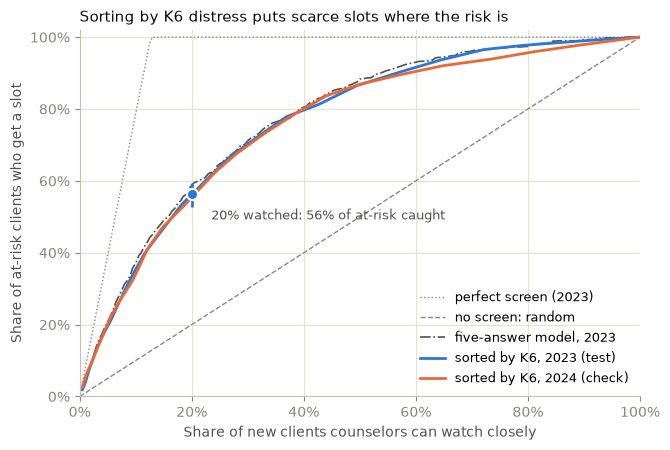

In [11]:
CAPS = np.array([0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50])

def slots(score, w, cap):
    """Each client's share of a slot (0 to 1) when the top `cap` of clients by score get one.
    Clients with the same score are tied, so the score group at the cutoff shares the remaining slots equally."""
    t = pd.DataFrame({"s": np.round(score, 10), "w": w})
    g = t.groupby("s").w.sum().sort_index(ascending=False)
    cw = g.cumsum() / g.sum()
    prev = cw.shift(fill_value=0)
    return t.s.map(((cap - prev) / (cw - prev)).clip(0, 1)).to_numpy()

def caught(score, d, caps):
    """Share of at-risk clients (weighted) who get a slot, at each capacity."""
    y, w = d.at_risk.to_numpy(), d.ANALWT2_C.to_numpy()
    return np.array([(w * y * slots(score, w, c)).sum() / (w * y).sum() for c in np.atleast_1d(caps)])

def caught_by_age(score, d, cap):
    """Share of at-risk clients in each age group who get a slot."""
    y, w = d.at_risk.to_numpy(), d.ANALWT2_C.to_numpy()
    t = pd.DataFrame({"age": d.age.to_numpy(), "wy": w * y, "wys": w * y * slots(score, w, cap)})
    g = t.groupby("age", observed=True).sum()
    return g.wys / g.wy

k6_score = lambda d: d.KSSLR6MON.to_numpy().astype(float)     # the rule: sort by K6, no fitted model
p_model = lambda m, d: m.predict(design(d)).to_numpy()        # the alternative: the five-answer model

# Intervals: the same Rao-Wu cluster bootstrap, seed 603. The K6 ranking has nothing to refit, so its
# interval comes from resampling the scored year. The five-answer model is refit on each 2022 replicate.
cap_rng = np.random.default_rng(SEED + 3)
cap_reps = {"2023": [], "2024": []}
age_reps = {"2023": [], "2024": []}
for b in range(B):
    tr, te, ch = half_sample(train, cap_rng), half_sample(test, cap_rng), half_sample(check, cap_rng)
    w = tr.ANALWT2_C / tr.ANALWT2_C.mean()
    m_b = sm.GLM(tr.at_risk, design(tr), family=sm.families.Binomial(), var_weights=w).fit()
    for yr, d in [("2023", te), ("2024", ch)]:
        k, f = caught(k6_score(d), d, CAPS), caught(p_model(m_b, d), d, CAPS)
        cap_reps[yr].append(np.concatenate([k, f, f - k]))
        age_reps[yr].append(caught_by_age(k6_score(d), d, 0.20))

n = len(CAPS)
cap = {}
for yr, d in [("2023", test), ("2024", check)]:
    rate = wmean(d.at_risk, d.ANALWT2_C)
    arr = np.array(cap_reps[yr])
    lo, hi = np.percentile(arr, 2.5, axis=0), np.percentile(arr, 97.5, axis=0)
    k, f = caught(k6_score(d), d, CAPS), caught(p_model(model, d), d, CAPS)
    cap[yr] = pd.DataFrame({
        "K6 rule": k, "K6 low": lo[:n], "K6 high": hi[:n],
        "five-answer model": f, "model low": lo[n:2 * n], "model high": hi[n:2 * n],
        "model - K6": f - k, "diff low": lo[2 * n:], "diff high": hi[2 * n:],
        "random": CAPS,
        "at-risk on close per 100, K6": 100 * rate * k,
        "at-risk on close per 100, random": 100 * rate * CAPS,
    }, index=pd.Index(CAPS, name="capacity (share of new clients watched)"))
    print(f"Share of at-risk clients who get a slot, {yr}")
    display(cap[yr].round(3))

# The K6 score at the cutoff, and the r above which filling the slots is worth it.
# A K6-only logistic regression, fit on 2022, turns the cutoff score into a risk p. Giving the marginal
# client a slot pays when r * p > 1 - p, so when r > (1 - p) / p.
X_k6 = lambda k: sm.add_constant(pd.DataFrame({"k6": np.asarray(k, float)}), has_constant="add")
model_k6 = sm.GLM(train.at_risk.to_numpy(), X_k6(train.KSSLR6MON), family=sm.families.Binomial(),
                  var_weights=w_train.to_numpy()).fit()
def cutoff(d, c):
    s = pd.Series(slots(k6_score(d), d.ANALWT2_C.to_numpy(), c), index=k6_score(d))
    by = s.groupby(level=0).first().sort_index(ascending=False)
    edge = by[by > 0].index.min()                       # lowest K6 score that gets any slot
    return edge, by[edge]
rows = []
for c in CAPS:
    edge, share = cutoff(test, c)
    p_edge = np.asarray(model_k6.predict(X_k6([edge])))[0]
    rows.append({"capacity": c, "lowest K6 with a slot": int(edge), "share of that score given a slot": share,
                 "risk at that score (K6-only fit, 2022)": p_edge, "slots worth filling when r >": (1 - p_edge) / p_edge})
binds = pd.DataFrame(rows).set_index("capacity")
print("Where the K6 cutoff falls on 2023, and the r above which filling the slots is worth it")
display(binds.round(3))

# Who gets the slots, by age group, at 20% capacity.
by_age_cap = {}
for yr, d in [("2023", test), ("2024", check)]:
    w = d.ANALWT2_C.to_numpy()
    s = slots(k6_score(d), w, 0.20)
    arr = pd.DataFrame(age_reps[yr])
    by_age_cap[yr] = pd.DataFrame({
        "n": d.groupby("age", observed=True).size(),
        "at risk, n": d.groupby("age", observed=True).at_risk.sum(),
        "share given a slot, K6": pd.Series(w * s).groupby(d.age.to_numpy(), observed=True).sum()
                                  / pd.Series(w).groupby(d.age.to_numpy(), observed=True).sum(),
        "at-risk given a slot, K6": caught_by_age(k6_score(d), d, 0.20),
        "low": arr.quantile(0.025), "high": arr.quantile(0.975),
        "at-risk given a slot, five-answer model": caught_by_age(p_model(model, d), d, 0.20),
    })
    print(f"Who gets the slots at 20% capacity, by age group, {yr}")
    display(by_age_cap[yr].round(3))

# The capture curve: share of at-risk clients caught against the share of clients watched.
grid = np.linspace(0.005, 1, 200)
fig, ax = plt.subplots(figsize=(6.8, 4.6))
p23 = wmean(test.at_risk, test.ANALWT2_C)
ax.plot(grid, np.minimum(1, grid / p23), color="#898781", lw=1, ls=":", label="perfect screen (2023)")
ax.plot([0, 1], [0, 1], color="#898781", lw=1, ls="--", label="no screen: random")
ax.plot(grid, caught(p_model(model, test), test, grid), color="#52514e", lw=1.2, ls="-.", label="five-answer model, 2023")
for yr, d in [("2023", test), ("2024", check)]:
    ax.plot(grid, caught(k6_score(d), d, grid), color=COLORS_YR[yr], lw=2,
            label=f"sorted by K6, {yr} ({'test' if yr == '2023' else 'check'})")
c23 = cap["2023"].loc[0.20]
ax.errorbar([0.20], [c23["K6 rule"]], yerr=[[c23["K6 rule"] - c23["K6 low"]], [c23["K6 high"] - c23["K6 rule"]]],
            color=COLORS_YR["2023"], marker="o", ms=8, markeredgecolor="#fcfcfb", markeredgewidth=1.5, lw=0, elinewidth=2)
ax.annotate(f"20% watched: {c23['K6 rule']:.0%} of at-risk caught", (0.20, c23["K6 rule"]),
            xytext=(14, -18), textcoords="offset points", fontsize=9, color="#52514e")
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("Share of new clients counselors can watch closely", color="#52514e")
ax.set_ylabel("Share of at-risk clients who get a slot", color="#52514e")
ax.set_title("Sorting by K6 distress puts scarce slots where the risk is", loc="left", fontsize=11, color="#0b0b0b")
ax.grid(color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
for side in ("left", "bottom"): ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "capacity.png", dpi=150); plt.show()


**Reading.** Sorting by K6 puts the scarce slots where the risk is, and the five-answer model does not clearly do better.

- **The rule.** If counselors can watch 1 in 5 new clients closely, sorting by K6 gives a slot to 56.2% of at-risk clients on 2023 (95% interval 52.7% to 59.5%), against 20% at random. That is 7.1 at-risk clients on close monitoring per 100 new clients, against 2.5. On 2024 it is 55.4% (51.4% to 58.9%).
- **In plain words.** At 20% capacity, every new client with a K6 of 13 or more gets a slot, and so do 43% of those who score 12. A K6 of 13 or more is the survey's own definition of serious psychological distress (`SPDPSTMON`).
- **Against the five-answer model.** The model catches 58.9% on 2023 and 57.0% on 2024. The difference from K6 is 2.7 points on 2023 (−0.9 to 3.9) and 1.6 on 2024 (−1.1 to 4.4). At every capacity from 5% to 50%, in both years, the interval for the difference includes zero. The model asks four more questions for a gain the data cannot confirm.
- **Other capacities.** At 10% capacity K6 reaches 35% of at-risk clients against 10% at random, and at 50%, 87% against 50%.
- **The risk that remains.** At 20% capacity, 44% of at-risk clients still start on standard monitoring, 5.6 per 100 new clients.
- **Value of being less wrong.** A perfect screen would give every at-risk client a slot once 13% of clients can be watched. K6 reaches 56% at 20%, so better predictors are worth up to 5.6 more at-risk clients on close monitoring per 100 new clients. Raising capacity from 20% to 30% adds 1.8 (7.1 to 8.9).

**When does r still matter?** A slot is worth filling when the client's risk p satisfies r · p > 1 − p. At 20% capacity the last client to get a slot scores 12, where the risk is about 20%, so filling all the slots pays when r is above about 4. At 10% capacity it is r above 2.2, and at 30%, r above 6.2. My central estimates of r (14 and up) are above all of these. The weak end of the attempts-only estimate, r of 2 to 3, is not: there, some slots at 20% capacity should stay empty. So "the answer does not depend on r" holds for the ranking, and for filling the slots it holds only above these values.

**Who gets the slots, by age.** At 20% capacity on 2023, K6 gives a slot to 66% of at-risk clients aged 18–25 and to 40% of those 65 and over (95% interval 21% to 60%; 48 at-risk respondents). On 2024 it is 62% against 22% (7% to 41%; 38 respondents). The five-answer model is far more uneven, because age is one of its answers: 81% at 18–25 against 10% at 65 and over on 2023, and 78% against 6% on 2024. Under either rule, at-risk older clients are the least likely to get a slot. With K6 the 2023 interval for 65 and over still reaches the other age groups. With the model it is half the rate of a random pick.

If time were unlimited, the r-based loss above applies instead: the screen clearly pays up to r = 29, and from r = 50 the data cannot tell.

### Alternatives: does anything beat sorting by K6?

The model entry of 2026-11-06 in `decisions.md` left two things open: whether sex, overall health, employment, or a count of depression symptoms would help, and whether a tree would do better than a logistic regression. This cell checks both.

Each candidate is scored by cross-validation inside 2022, the training year: five folds of whole clusters (100 clusters, seed 604), so no cluster is on both sides of a split. The score is the share of at-risk clients caught, at 10% and 20% capacity, averaged over the five held-out folds. The 2023 and 2024 columns are shown for the record. They were not used to choose.

The candidates: the five answers without age; the five plus sex (`IRSEX`), overall health (`HEALTH2`, 1 excellent to 4 fair or poor), employment (`IRWRKSTAT18`), or the number of depression symptoms 1 to 8 (`AD_MDEA1`–`AD_MDEA8`); the five plus all four; and classification trees of depth 3 and 5 with at least 100 respondents in a leaf. Symptom 9, thoughts of death, is left out because it contains the outcome. The symptom questions describe the worst episode of the person's life, and they are asked only of respondents who report a period of depression; everyone else counts as zero.

In [12]:
from sklearn.tree import DecisionTreeClassifier

# Candidate extra predictors (named under Revisit in decisions.md, 2026-11-06).
SYM = [f"AD_MDEA{k}" for k in range(1, 9)]
def design_x(d, extras=(), age=True):
    X = design(d)
    if not age:
        X = X.drop(columns=[c for c in X.columns if c.startswith("age_")])
    if "sex" in extras:
        X["female"] = (d.IRSEX == 2).astype(float)
    if "health" in extras:                               # 1 excellent to 4 fair/poor; 2 to 5 unknowns a year set to 3
        X["health"] = d.HEALTH2.fillna(3).astype(float)
    if "work" in extras:                                 # reference: employed full time
        for code, name in [(2, "part_time"), (3, "unemployed"), (4, "other_work")]:
            X[name] = (d.IRWRKSTAT18 == code).astype(float)
    if "symptoms" in extras:                             # depression symptoms 1-8 in the worst episode; 0 if not asked
        X["symptoms"] = (d[SYM] == 1).sum(axis=1).astype(float)
    return X

def fit_logit(tr, **kw):
    w = tr.ANALWT2_C / tr.ANALWT2_C.mean()
    m = sm.GLM(tr.at_risk, design_x(tr, **kw), family=sm.families.Binomial(), var_weights=w).fit()
    return lambda d: m.predict(design_x(d, **kw)).to_numpy()

def fit_tree(tr, depth, **kw):
    cols = lambda d: design_x(d, **kw).drop(columns="const")
    t = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=100, random_state=SEED)
    t.fit(cols(tr), tr.at_risk, sample_weight=tr.ANALWT2_C)
    return lambda d: t.predict_proba(cols(d))[:, 1]

ALL = ("sex", "health", "work", "symptoms")
CANDIDATES = {
    "K6 alone (the rule)":              lambda tr: k6_score,
    "five answers (logistic)":          lambda tr: fit_logit(tr),
    "five answers without age":         lambda tr: fit_logit(tr, age=False),
    "five + sex":                       lambda tr: fit_logit(tr, extras=("sex",)),
    "five + overall health":            lambda tr: fit_logit(tr, extras=("health",)),
    "five + employment":                lambda tr: fit_logit(tr, extras=("work",)),
    "five + depression symptoms":       lambda tr: fit_logit(tr, extras=("symptoms",)),
    "five + all four":                  lambda tr: fit_logit(tr, extras=ALL),
    "tree, five answers, depth 3":      lambda tr: fit_tree(tr, 3),
    "tree, five answers, depth 5":      lambda tr: fit_tree(tr, 5),
    "tree, five + all four, depth 5":   lambda tr: fit_tree(tr, 5, extras=ALL),
}

# Cross-validation inside 2022: five folds of whole clusters (100 clusters, seed 604), so no cluster is
# on both sides. The score is the share of at-risk clients caught, averaged over the five held-out folds.
cv_rng = np.random.default_rng(SEED + 4)
cluster = train.VESTR_C.astype(str) + "-" + train.VEREP.astype(str)
ids = cluster.unique()
fold_of = dict(zip(cv_rng.permutation(ids), np.arange(len(ids)) % 5))
fold = cluster.map(fold_of).to_numpy()

rows = {}
for name, make in CANDIDATES.items():
    cv = np.array([caught(make(train[fold != k])(train[fold == k]), train[fold == k], [0.10, 0.20]) for k in range(5)])
    score = make(train)                                  # refit on all of 2022 for the held-out years
    rows[name] = {"CV 2022, 10%": cv[:, 0].mean(), "CV 2022, 20%": cv[:, 1].mean(), "sd across folds, 20%": cv[:, 1].std(ddof=1),
                  "2023, 20%": caught(score(test), test, [0.20])[0], "2024, 20%": caught(score(check), check, [0.20])[0]}
alts = pd.DataFrame(rows).T
print("Share of at-risk clients caught. Choose on the CV columns; 2023 and 2024 are shown, not used to choose.")
display(alts.round(3))

# The r-based check with a K6-only logistic regression in place of the five-answer model.
def loss_at(p_hat, d, r):
    return np.array([loss_per_100(d.at_risk.to_numpy(), (p_hat > 1 / (1 + r_)).astype(int), d.ANALWT2_C, r_) for r_ in r])
r_check = pd.DataFrame({
    "baseline 2023": scores["baseline 2023"],
    "five-answer model 2023": scores["model 2023"],
    "K6-only logistic 2023": loss_at(np.asarray(model_k6.predict(X_k6(test.KSSLR6MON))), test, R_GRID),
}, index=scores.index)
r_check["K6-only minus five-answer"] = r_check.iloc[:, 2] - r_check.iloc[:, 1]
print("Loss per 100 new clients on 2023, if time were unlimited")
display(r_check.round(2))


Share of at-risk clients caught. Choose on the CV columns; 2023 and 2024 are shown, not used to choose.


,"CV 2022, 10%","CV 2022, 20%","sd across folds, 20%","2023, 20%","2024, 20%"
K6 alone (the rule),0.346,0.583,0.053,0.562,0.554
five answers (logistic),0.373,0.591,0.046,0.589,0.570
five answers without age,0.361,0.581,0.043,0.573,0.565
five + sex,0.369,0.591,0.035,0.566,0.578
five + overall health,0.371,0.594,0.052,0.570,0.573
five + employment,0.367,0.591,0.058,0.581,0.565
five + depression symptoms,0.386,0.607,0.034,0.605,0.581
five + all four,0.395,0.608,0.040,0.601,0.596
"tree, five answers, depth 3",0.316,0.574,0.063,0.557,0.556
"tree, five answers, depth 5",0.336,0.561,0.059,0.551,0.552


Loss per 100 new clients on 2023, if time were unlimited


,baseline 2023,five-answer model 2023,K6-only logistic 2023,K6-only minus five-answer
r,,,,
2,25.43,21.26,22.04,0.77
5,63.56,39.28,40.21,0.93
10,87.29,54.54,56.13,1.59
14,87.29,60.75,62.49,1.75
29,87.29,71.74,75.01,3.27
35,87.29,76.76,80.07,3.30
40,87.29,79.07,80.98,1.91
50,87.29,79.74,87.29,7.54
100,87.29,84.88,87.29,2.41


**Reading.** Nothing here clearly beats sorting by K6.

- **Extra predictors.** In cross-validation K6 alone catches 58.3% of at-risk clients at 20% capacity. The five-answer model catches 59.1%. Adding sex, overall health, or employment leaves that where it is (59.1% to 59.4%). Adding the depression symptom count gives 60.7%, and all four together 60.8%. That is 2.5 points above K6, and the scores differ by 3 to 6 points from fold to fold. At 10% capacity the gap is larger: 39.5% for all four against 34.6% for K6. The held-out years say the same: 60.1% and 59.6% for all four, against 56.2% and 55.4% for K6.
- **So the symptom count is the one candidate worth a second look.** It is the first sign of what "better answers" might be. I did not adopt it: the gain at 20% is inside the fold-to-fold spread, and the questions are about the worst episode of a lifetime, not about the client at intake.
- **Trees.** None beats the logistic regression on the same answers: 57.4% and 56.1% for the five answers at depth 3 and 5, against 59.1%, and 58.7% with all four extras, against 60.8%. A tree cuts K6 into a few steps, and the risk rises smoothly with K6, so the steps lose information.
- **Age.** Dropping age from the five-answer model costs 1.0 point in cross-validation (58.1% against 59.1%).
- **If time were unlimited.** A logistic regression on K6 alone costs 0.8 to 3.3 more per 100 new clients than the five-answer model for r from 2 to 40, and still beats the baseline there. From r = 50 its threshold puts everyone on close monitoring, so it ties the baseline. The five-answer model stays the tool for that check.

## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.


In [13]:
# Key effects in real units: predicted risk for a few example new clients.
examples = pd.DataFrame([
    {"who": "30, low distress (K6 4), nothing else",           "age": "26-34", "KSSLR6MON": 4,  "UD5ILALANY": 0, "IRMHTRXMED": 0, "IRMHTPHVID": 0},
    {"who": "30, high distress (K6 16), nothing else",          "age": "26-34", "KSSLR6MON": 16, "UD5ILALANY": 0, "IRMHTRXMED": 0, "IRMHTPHVID": 0},
    {"who": "22, high distress, substance use disorder, on Rx", "age": "18-25", "KSSLR6MON": 16, "UD5ILALANY": 1, "IRMHTRXMED": 1, "IRMHTPHVID": 0},
    {"who": "70, low distress (K6 4), on Rx",                   "age": "65+",   "KSSLR6MON": 4,  "UD5ILALANY": 0, "IRMHTRXMED": 1, "IRMHTPHVID": 0},
])
examples["age"] = pd.Categorical(examples.age, categories=list(AGE.values()), ordered=True)
examples["predicted risk"] = model.predict(design(examples)).to_numpy()
for r_ in [10, 29]:
    examples[f"close at r={r_}?"] = np.where(examples["predicted risk"] > 1 / (1 + r_), "yes", "no")
display(examples.set_index("who")[["predicted risk", "close at r=10?", "close at r=29?"]].round(3))


,predicted risk,close at r=10?,close at r=29?
who,,,
"30, low distress (K6 4), nothing else",0.028,no,no
"30, high distress (K6 16), nothing else",0.209,yes,yes
"22, high distress, substance use disorder, on Rx",0.501,yes,yes
"70, low distress (K6 4), on Rx",0.018,no,no


**Key effects in plain language.** The rule: at 20% capacity, a new client with a K6 of 13 or more starts on close monitoring, and so do 43% of those who score 12. That catches 56% of at-risk clients, 7.1 per 100 new clients, against 2.5 with no screen.

In the five-answer model, distress is also the strongest signal: each point on the K6 scale (0 to 24) multiplies the odds of serious thoughts of suicide by 1.20. A 30-year-old with low distress (K6 4) has a predicted risk of 2.8%. The same person with high distress (K6 16) is at 20.9%. A 22-year-old with high distress, a substance use disorder, and psychiatric medication is at 50%. A 70-year-old with low distress who takes medication is at 1.8%. A drug or alcohol use disorder multiplies the odds by 1.43, medication by 1.50, and phone or video treatment by 1.30. Adults 65 and over have about a quarter of the odds of 18–25-year-olds.

**Where not to trust the result.**

- For older clients. At 20% capacity, K6 gives a slot to 40% of at-risk clients aged 65 and over on 2023 and 22% on 2024, against 66% and 62% at 18–25. The 65-and-over figures rest on 48 and 38 respondents. The outcome is thoughts of suicide, not attempts or deaths, and the screen was not checked against either.
- When r is below about 4. Then not every slot at 20% capacity is worth filling.
- If counselors could watch everyone. Then the r-based loss applies: the screen clearly pays up to r = 29, and from r = 50 the data cannot tell whether it beats starting everyone on close monitoring.
- Predicted risks above about 30% from the five-answer model: they are too high, more so on 2024. No threshold in use is that high.
- For FirstHarbor's actual clients. They are invited by counselors, use an app, and are scored at intake, not over the past year. K6 covers the past month and the outcome the past year, and the survey cannot say whether the thoughts of suicide came before or after treatment began.
- After the definition of treatment changes again, as it did in 2022 and in June 2024.

**What was assumed.**

- Without a screen the slots go to a random pick of new clients. A counselor's own judgment would do better than random, and the survey cannot measure it. So 56% against 20% overstates what K6 adds to a counselor.
- The capacity levels (5% to 50%) are illustrations: FirstHarbor's counselors have not given theirs.
- The range of r, 2 to 500. It rests on Stanley et al. (2018), where the safety plan, not the number of calls, seemed to do the work, and on an assumed 30 to 60 minutes of counselor review.
- The outcome is serious thoughts of suicide, while the cost of a miss comes from suicidal behavior that was prevented.
- About 2% of the outcome values were imputed by SAMHSA.

**With more time or data.**

- Ask counselors what share of new clients they can watch closely in week 1. That sets the capacity, and the slots go to the highest K6.
- Ask counselors how they pick whom to watch now. That is the real baseline, not a random pick.
- Ask counselors for r. It no longer decides whether to build the screen. It decides whether every slot is worth filling and whether more counselor time is worth paying for.
- Test the depression symptom count with questions about the present, not the worst episode. It was the only extra answer that looked useful.
- Once FirstHarbor has clients, score the rule on their own intake answers and first weeks, by age group.
- Use the restricted NSDUH files, which carry the interview month, to separate the old and new 2024 wording.
